<a href="https://colab.research.google.com/github/harleycooper2006/Data-Analysis-and-Machine-Learning/blob/main/Week_2_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, ConfusionMatrixDisplay

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/CMP6202/datasets/breast_cancer_wisconsin.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
df["is_malignant"] = df["diagnosis"].map({"B": 0, "M": 1})

df = df.drop(columns=["diagnosis", "id"])

df.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,is_malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [ ]:
print("Rows, columns:", df.shape)
print("Missing values:", df.isna().sum().sum())

Rows, columns: (569, 31)
Missing values: 0


is_malignant
0    357
1    212
Name: count, dtype: int64


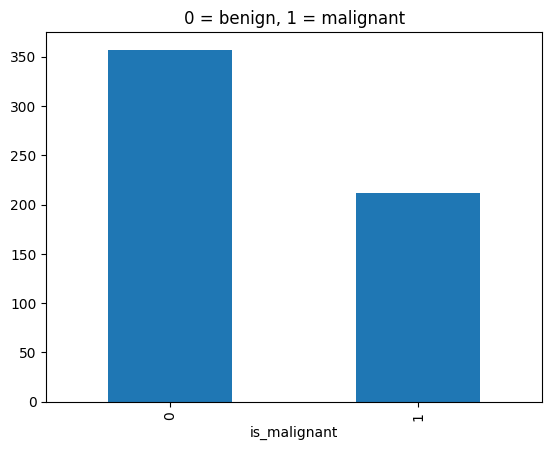

In [ ]:
print(df["is_malignant"].value_counts())

df["is_malignant"].value_counts().plot(kind="bar", title="0 = benign, 1 = malignant")
plt.show()

In [ ]:
X = df.drop(columns=["is_malignant"])
y = df["is_malignant"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 341
Validation: 114
Test: 114


In [ ]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_val)

print("Accuracy:", accuracy_score(y_val, baseline_pred))
print("Recall:", recall_score(y_val, baseline_pred))

Accuracy: 0.6228070175438597
Recall: 0.0


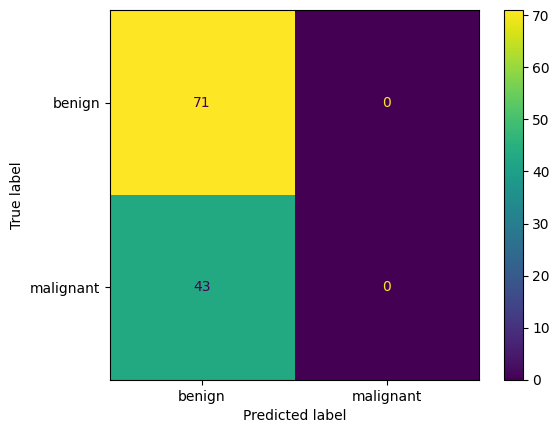

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_val, baseline_pred, display_labels=["benign", "malignant"])
plt.show()

In [ ]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

model_pred = model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, model_pred))
print("Recall:", recall_score(y_val, model_pred))

Accuracy: 0.9736842105263158
Recall: 0.9767441860465116


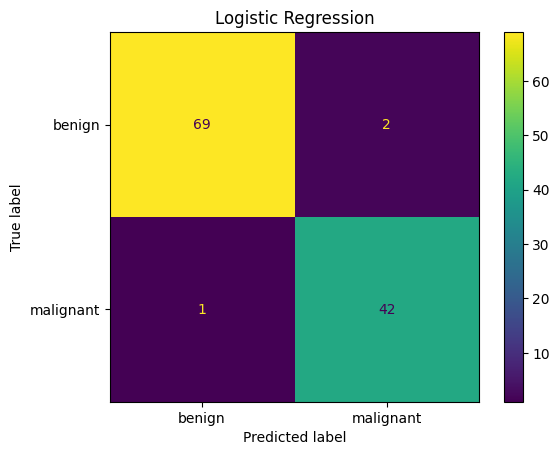

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_val, model_pred, display_labels=["benign", "malignant"])
plt.title("Logistic Regression")
plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": ["baseline", "logistic regression"],
    "Accuracy": [accuracy_score(y_val, baseline_pred), accuracy_score(y_val, model_pred)],
    "Recall": [recall_score(y_val, baseline_pred), recall_score(y_val, model_pred)]
})

results.round(3)


,Model,Accuracy,Recall
0,baseline,0.623,0.000
1,logistic regression,0.974,0.977


Test accuracy: 0.9736842105263158
Test recall: 0.9523809523809523


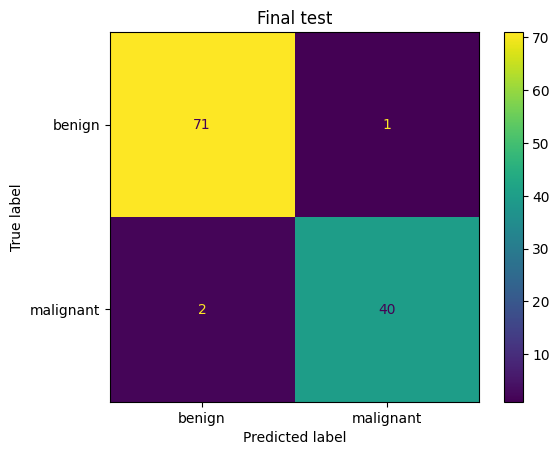

In [ ]:
test_pred = model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, test_pred))
print("Test recall:", recall_score(y_test, test_pred))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["benign", "malignant"])
plt.title("Final test")
plt.show()